# FoAI Coursework: week 1 of work (data cleaning)

In [146]:
#Importing

from pathlib import Path
import warnings
import datetime # needed to add this to be able to format the dates correctly

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# DATA CLEANING AND FEATURE ENGINEERING
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# CLUSTERING AND DIMENSIONALITY REDUCTION
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

#DATA TRAINING AND EVALUTATING MODEL
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#REGRESSION MODELS
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [147]:
#Loading dataset into notebook
DATA_PATH = Path("MedHealth_SYNTHEA_GroupCW_Dataset_Final.csv")


ID_COLUMN = ["PATIENT_ID"]


if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put the CSV file in the same folder as this notebook."
    )

#ensuring correct format of data is compatible with uploading

suffix = DATA_PATH.suffix.lower()
if suffix == ".csv":
    data = pd.read_csv(DATA_PATH)
elif suffix in {".xlsx", ".xls"}:
    data = pd.read_excel(DATA_PATH)
elif suffix == ".parquet":
    data = pd.read_parquet(DATA_PATH)
else:
    raise ValueError("Supported formats: CSV, Excel, and Parquet.")

raw = pd.read_csv(DATA_PATH)
print(f"Loaded {raw.shape[0]:,} rows and {raw.shape[1]:,} columns.")
display(raw.head())
#display(raw)

Loaded 297 rows and 52 columns.


,PATIENT_ID,BIRTH_DATE,SEX,RACE,YEAR,PERIOD_START,PERIOD_END,RECORD_CUTOFF_DATE,ENCOUNTER_SYMPTOM_RECORDS,ENCOUNTER_CHECK_UP_RECORDS,...,HYPERTENSION_HISTORY,ISCHEMIC_HEART_DISEASE_HISTORY,HYPERLIPIDEMIA_HISTORY,CHRONIC_PAIN_HISTORY,ASTHMA_HISTORY,CHRONIC_KIDNEY_DISEASE_HISTORY,STRESS_HISTORY,SOCIAL_ISOLATION_HISTORY,UNEMPLOYMENT_HISTORY,HOUSING_UNSATISFACTORY_HISTORY
0,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,20/01/1981,F,white,2023,01/01/2023,31/12/2023,25/08/2026,0,0,...,1,0,0,0,0,0,1,1,0,0
1,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,20/01/1981,F,white,2024,01/01/2024,31/12/2024,25/08/2026,0,0,...,1,0,0,0,0,0,1,1,0,0
2,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,20/01/1981,F,white,2025,01/01/2025,31/12/2025,25/08/2026,0,1,...,1,0,0,0,0,0,1,1,0,0
3,029c95e2-d252-d8d3-3626-7f347182d6d7,01/11/1972,F,white,2023,01/01/2023,31/12/2023,19/08/2026,0,0,...,0,0,0,1,0,0,1,1,0,0
4,029c95e2-d252-d8d3-3626-7f347182d6d7,01/11/1972,F,white,2024,01/01/2024,31/12/2024,19/08/2026,0,2,...,0,0,0,1,0,0,1,1,0,0


In [148]:
#Dataset structure inspection - identifying data type, missing values, unique values and duplicates
display(pd.DataFrame({
    "data_type": data.dtypes.astype(str),
    "missing_n": data.isna().sum(),
    "missing_percent": (100 * data.isna().mean()).round(1),
    "unique_values": data.nunique(dropna=True),
}).sort_values("missing_percent", ascending=False))

print("Exact Duplicate rows:", data.duplicated().sum())
display(data.describe(include="all").T)


,data_type,missing_n,missing_percent,unique_values
GLUCOSE_LAST_RECORDED,float64,176,59.3,107
GLUCOSE_DATE,object,176,59.3,101
CREATININE_LAST_RECORDED,float64,176,59.3,83
CREATININE_DATE,object,176,59.3,101
TRIGLYCERIDES_LAST_RECORDED,float64,128,43.1,96
TRIGLYCERIDES_DATE,object,128,43.1,97
HDL_CHOLESTEROL_DATE,object,128,43.1,97
HDL_CHOLESTEROL_LAST_RECORDED,float64,128,43.1,99
TOTAL_CHOLESTEROL_DATE,object,128,43.1,97
TOTAL_CHOLESTEROL_LAST_RECORDED,float64,128,43.1,99


Exact Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PATIENT_ID,297,100,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BIRTH_DATE,297,96,06/11/1979,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEX,297,2,M,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RACE,297,3,white,242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEAR,297.0,NaN,NaN,NaN,2024.0,0.817875,2023.0,2023.0,2024.0,2025.0,2025.0
PERIOD_START,297,6,01/01/2025,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PERIOD_END,297,4,31/12/2024,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RECORD_CUTOFF_DATE,297,10,23/08/2026,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENCOUNTER_SYMPTOM_RECORDS,297.0,NaN,NaN,NaN,0.296296,0.636518,0.0,0.0,0.0,0.0,5.0
ENCOUNTER_CHECK_UP_RECORDS,297.0,NaN,NaN,NaN,0.804714,1.795898,0.0,0.0,0.0,1.0,15.0


Data reflection:
1. one row respresents 1 patient in each year - so to note there are only 100 unique patient IDs but most patients are in all 3 years so are lots of data for the same person.
--> however there are no duplicate rows which is good as it means there's no repeats of the exact same patients information for the same presentation that we need to clean.
2. LOTS OF MISSING VALUES FOR BLOODS:
*    What to do with glucose(delete whole group), creatinine, total cholesterol and HDL and triglycerides
*   Team dsicussion required for how we want to manage this - possible take an average for that patient if the same patient is duplicated across the 3 years
3. only 2 unique sex's (good in this sense because don't need to account for "m" and "M" etc)
4. Only 3 unique races accounted for - significant limitation --> we can't generalise this to other populations its either white black or asian - what about any other race? Any findings are not generalisable to different population group that is more diverse --> and it's a very white patient data set with frequency of white being 242.
5. Note there are different period cut off's - this is important as may want to exclude some patients if their encounter is less than a year as it could be not representative - for group discussion. (in the end did delete these).
6. Not clear what a problem encounter is? The rest make sense - exam, prenatal etc.
7. why are there multiple different values for record cut off date if this is the date that they collected the data from?--> this is actually fine, all the values for this are in Aug 2026, and all the data was collected before this point so this is not an issue
8. Some extremes of values:
* Did someone really go to the ER 33 times in one year?
* 179 new medications in one year?!
* 180 something procedures in one year!
9. Some ideas for feature engineering from reviewing the data at this point:
* Do I want to subtract screening and dental procedures from total procedures to extract the data for "all other" procedures
* BMI
10. Lots of children: raises the issue that kids medically are very different to adults - trends in children are not necessarily similar to those in adults. Would be useful to explore the adult population seperately to the children.


In [149]:
#Making a copy
data = data.copy()

#Identifing columns to clean that are string/categorical types
columns_to_clean = ["GLUCOSE_LAST_RECORDED", "GLUCOSE_DATE", "CREATININE_LAST_RECORDED", "CREATININE_DATE", "TRIGLYCERIDES_LAST_RECORDED",
                    "TRIGLYCERIDES_DATE", "HDL_CHOLESTEROL_DATE", "HDL_CHOLESTEROL_LAST_RECORDED",
                    "TOTAL_CHOLESTEROL_LAST_RECORDED", "WEIGHT_KG_LAST_IN_YEAR","WEIGHT_KG_DATE", "HEIGHT_CM_DATE", "HEIGHT_CM_LAST_IN_YEAR",
                    "PAIN_SCORE_DATE", "PAIN_SCORE_LAST_IN_YEAR", "PATIENT_ID", "BIRTH_DATE", "SEX", "RACE", "ENCOUNTER_OTHER_RECORDS",
                    "ENCOUNTER_INPATIENT_RECORDS", "ENCOUNTER_FOLLOW_UP_RECORDS", "ENCOUNTER_POSTNATAL_RECORDS", "ENCOUNTER_WELL_CHILD_RECORDS",
                    "ENCOUNTER_URGENT_CARE_RECORDS", "ENCOUNTER_EMERGENCY_ROOM_RECORDS", "ENCOUNTER_GENERAL_EXAM_RECORDS", "ENCOUNTER_CHECK_UP_RECORDS",
                    "ENCOUNTER_SYMPTOM_RECORDS", "RECORD_CUTOFF_DATE", "PERIOD_END", "PERIOD_START", "YEAR", "SCREENING_ASSESSMENT_RECORDS",
                    "DENTAL_PROCEDURE_RECORDS", "PROCEDURE_RECORDS", "MEDICATION_START_RECORDS","OBESITY_HISTORY", "PREDIABETES_HISTORY",
                    "HYPERTENSION_HISTORY", "ISCHEMIC_HEART_DISEASE_HISTORY", "HYPERLIPIDEMIA_HISTORY",
                    "CHRONIC_PAIN_HISTORY", "ASTHMA_HISTORY", "CHRONIC_KIDNEY_DISEASE_HISTORY", "STRESS_HISTORY",
                    "SOCIAL_ISOLATION_HISTORY", "UNEMPLOYMENT_HISTORY", "HOUSING_UNSATISFACTORY_HISTORY"]

#Only strip and clean columns if they contain string/object-like data
for col in columns_to_clean:
    if data[col].dtype == object:
        data[col] = data[col].map(lambda value: np.nan if pd.isna(value) else str(value).strip())
        data[col] = data[col].replace(["nan","","na", "n/a","{nan}"], np.nan)

#Tried to standardize the times like we did in lab 2, got an error saying that time formats were different
#found the format=mixed function could get around that as can handle both DD/MM/YYYY and YYYY-MM-DD formats.
#Looks like didn’t make any difference, so essentially unnecsary code

for col in ["BIRTH_DATE", "PERIOD_START", "PERIOD_END", "RECORD_CUTOFF_DATE", "HEIGHT_CM_DATE",
            "WEIGHT_KG_DATE", "PAIN_SCORE_DATE", "TOTAL_CHOLESTEROL_DATE", "HDL_CHOLESTEROL_DATE",
            "TRIGLYCERIDES_DATE","GLUCOSE_DATE","CREATININE_DATE"]:
    data[col] = pd.to_datetime(data[col], format="mixed", errors="coerce")

#showing unique values once extra spaces have been removed and years have been standardised in format
display((data[columns_to_clean]).nunique(dropna=False))

,0
GLUCOSE_LAST_RECORDED,108
GLUCOSE_DATE,102
CREATININE_LAST_RECORDED,84
CREATININE_DATE,102
TRIGLYCERIDES_LAST_RECORDED,97
TRIGLYCERIDES_DATE,98
HDL_CHOLESTEROL_DATE,98
HDL_CHOLESTEROL_LAST_RECORDED,100
TOTAL_CHOLESTEROL_LAST_RECORDED,100
WEIGHT_KG_LAST_IN_YEAR,171


Looks like all of the categories were already standardised, except "year" as went from having (NaN) value in the unique colomn to having 3.

There must be a nan value somewhere that is being counted as a unique value. --> not sure if this is actually an issue? --> maybe this will fix itself after I have sorted out missing values

Didn't need to do cleaning for:


*   Sex: 2 unique items, so no issues with capitalisations e,g.
*   Race: 3 unique items, white, black and asian, so no issues with capitalisation or spaces

did for spaces just to be sure, but didn't actually need to.


Now time to come up with some rules: we are thinking here about implausible results.

In [150]:
# converting columns to numeric values first to resolve the TypeError
data["PAIN_SCORE_LAST_IN_YEAR"] = pd.to_numeric(data["PAIN_SCORE_LAST_IN_YEAR"], errors="coerce")
data["WEIGHT_KG_LAST_IN_YEAR"] = pd.to_numeric(data["WEIGHT_KG_LAST_IN_YEAR"], errors="coerce")
data["HEIGHT_CM_LAST_IN_YEAR"] = pd.to_numeric(data["HEIGHT_CM_LAST_IN_YEAR"], errors="coerce")

#making pain score 0-10
data.loc[(data["PAIN_SCORE_LAST_IN_YEAR"] < 0) | (data["PAIN_SCORE_LAST_IN_YEAR"] > 10)] = np.nan
data.loc[(data["WEIGHT_KG_LAST_IN_YEAR"] < 0) | (data["WEIGHT_KG_LAST_IN_YEAR"] > 250)] = np.nan
data.loc[(data["HEIGHT_CM_LAST_IN_YEAR"] < 0) | (data["HEIGHT_CM_LAST_IN_YEAR"] > 250)] = np.nan

display(pd.DataFrame({
    "missing_n_after_rules": data.isna().sum(),
    "missing_percent_after_rules": (100 * data.isna().mean()).round(1)
}).sort_values("missing_percent_after_rules", ascending=False))

,missing_n_after_rules,missing_percent_after_rules
GLUCOSE_LAST_RECORDED,176,59.3
GLUCOSE_DATE,176,59.3
CREATININE_LAST_RECORDED,176,59.3
CREATININE_DATE,176,59.3
TRIGLYCERIDES_LAST_RECORDED,128,43.1
TRIGLYCERIDES_DATE,128,43.1
HDL_CHOLESTEROL_DATE,128,43.1
HDL_CHOLESTEROL_LAST_RECORDED,128,43.1
TOTAL_CHOLESTEROL_DATE,128,43.1
TOTAL_CHOLESTEROL_LAST_RECORDED,128,43.1


#Visualise distributions and outliers

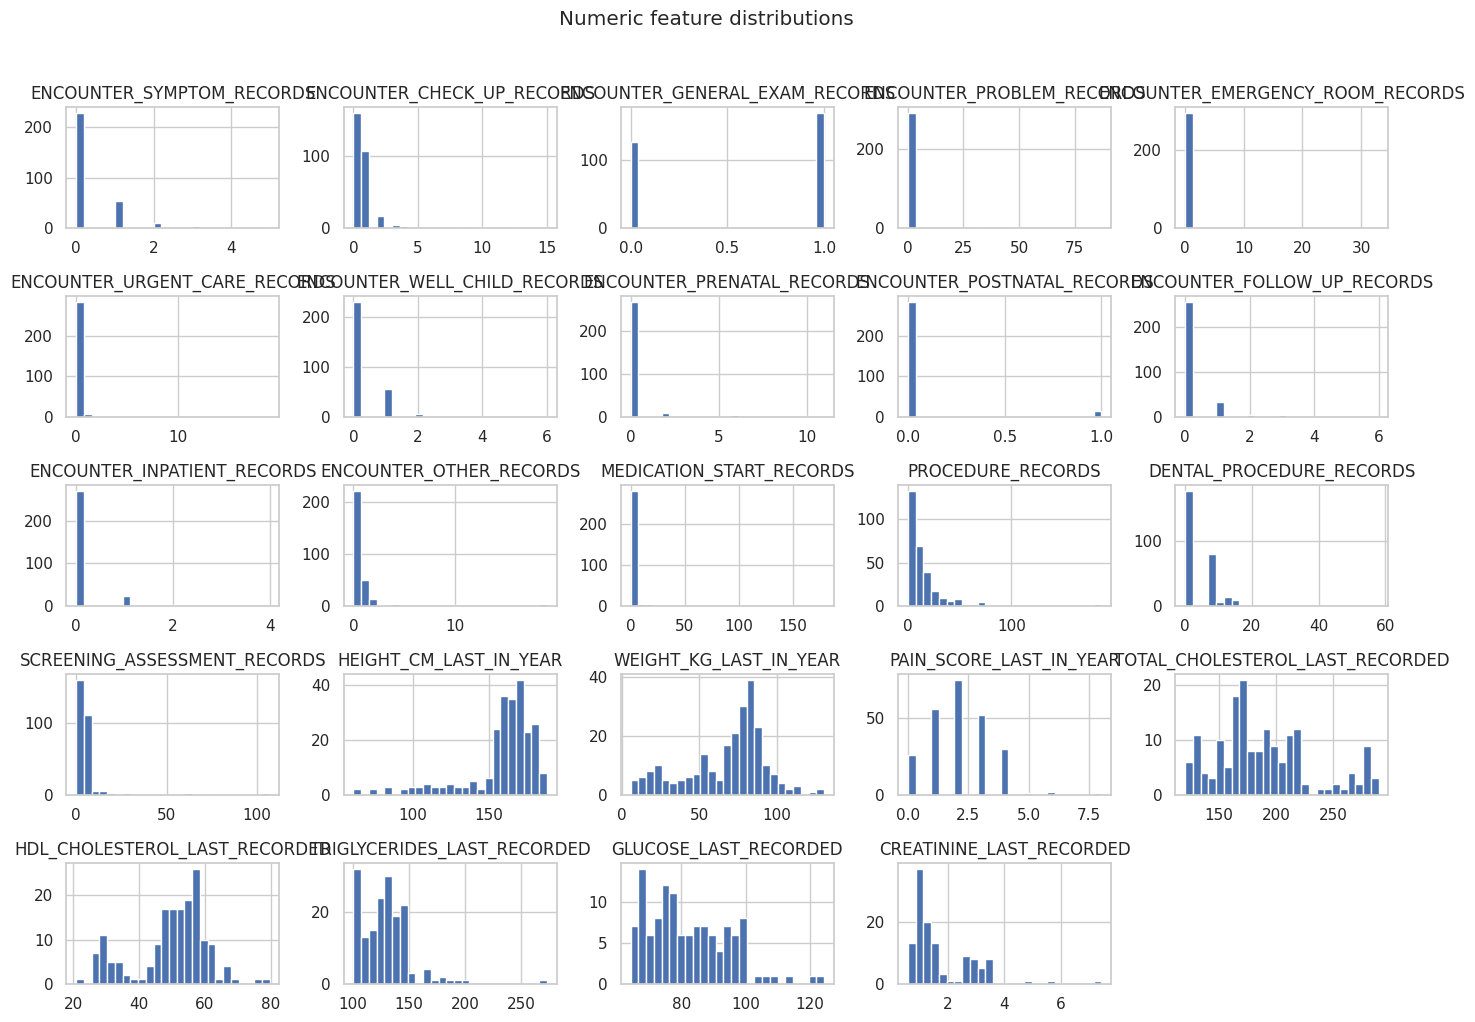

In [151]:
#making a histogram
numeric_cols = [
    "ENCOUNTER_SYMPTOM_RECORDS", "ENCOUNTER_CHECK_UP_RECORDS", "ENCOUNTER_GENERAL_EXAM_RECORDS", "ENCOUNTER_PROBLEM_RECORDS",
    "ENCOUNTER_EMERGENCY_ROOM_RECORDS", "ENCOUNTER_URGENT_CARE_RECORDS", "ENCOUNTER_WELL_CHILD_RECORDS", "ENCOUNTER_PRENATAL_RECORDS",
    "ENCOUNTER_POSTNATAL_RECORDS", "ENCOUNTER_FOLLOW_UP_RECORDS", "ENCOUNTER_INPATIENT_RECORDS",
    "ENCOUNTER_OTHER_RECORDS", "MEDICATION_START_RECORDS", "PROCEDURE_RECORDS", "DENTAL_PROCEDURE_RECORDS", "SCREENING_ASSESSMENT_RECORDS",
    "HEIGHT_CM_LAST_IN_YEAR", "WEIGHT_KG_LAST_IN_YEAR", "PAIN_SCORE_LAST_IN_YEAR",
    "TOTAL_CHOLESTEROL_LAST_RECORDED", "HDL_CHOLESTEROL_LAST_RECORDED", "TRIGLYCERIDES_LAST_RECORDED","GLUCOSE_LAST_RECORDED", "CREATININE_LAST_RECORDED"
]

data[numeric_cols].hist(figsize=(14, 10), bins=25)
plt.suptitle("Numeric feature distributions", y=1.02)
plt.tight_layout()
plt.show()

Cleaning to go back and do:
- investigating the medication start record outliers
- investing the procedures outliers
- screening assessment outlier

In [152]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr
    return lower, upper

col = "MEDICATION_START_RECORDS"
lower, upper = iqr_bounds(data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(data.loc[(data[col] < lower) | (data[col] > upper), ["PATIENT_ID", col]].head(10))

col = "SCREENING_ASSESSMENT_RECORDS"
lower, upper = iqr_bounds(data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(data.loc[(data[col] < lower) | (data[col] > upper), ["PATIENT_ID", col]].head(10))

col= "GLUCOSE_LAST_RECORDED"
lower, upper = iqr_bounds(data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(data.loc[(data[col] < lower) | (data[col] > upper), ["PATIENT_ID", col]].head(10))

MEDICATION_START_RECORDS: lower=-4.50, upper=7.50


,PATIENT_ID,MEDICATION_START_RECORDS
13,0f3d04a2-f42e-1429-acef-0becd0a0fcea,11
62,355a4d50-2628-aa65-c336-deacf4d606fb,8
63,355a4d50-2628-aa65-c336-deacf4d606fb,17
83,3c0e60c4-176e-2c4c-3b85-b46be390cf5e,18
106,5693c080-f485-91e7-54b9-ad9a8c12af62,17
108,5693c080-f485-91e7-54b9-ad9a8c12af62,76
112,57efda89-b582-bb08-8a2d-e06b2c184bfc,82
113,57efda89-b582-bb08-8a2d-e06b2c184bfc,86
114,57efda89-b582-bb08-8a2d-e06b2c184bfc,77
142,7af6b271-f16d-21e1-882a-7bff71005a7b,17


SCREENING_ASSESSMENT_RECORDS: lower=-9.00, upper=15.00


,PATIENT_ID,SCREENING_ASSESSMENT_RECORDS
13,0f3d04a2-f42e-1429-acef-0becd0a0fcea,19
61,355a4d50-2628-aa65-c336-deacf4d606fb,24
62,355a4d50-2628-aa65-c336-deacf4d606fb,29
63,355a4d50-2628-aa65-c336-deacf4d606fb,62
107,5693c080-f485-91e7-54b9-ad9a8c12af62,19
108,5693c080-f485-91e7-54b9-ad9a8c12af62,107
112,57efda89-b582-bb08-8a2d-e06b2c184bfc,29
113,57efda89-b582-bb08-8a2d-e06b2c184bfc,27
114,57efda89-b582-bb08-8a2d-e06b2c184bfc,47
216,bca1691f-8839-1d66-ed01-471134d55738,64


GLUCOSE_LAST_RECORDED: lower=46.53, upper=117.53


,PATIENT_ID,GLUCOSE_LAST_RECORDED
62,355a4d50-2628-aa65-c336-deacf4d606fb,121.24
113,57efda89-b582-bb08-8a2d-e06b2c184bfc,124.49


Here I have identified outliers for glucose, and even if this was taken after eating (which we don't know if it was fasted or not), this is still within the normal range - so we can conclude that we have no high glucose levels which we need to worry about. Lowest level is 64 which is only just considered to be low, and not necesarily clinically significant. Can't read into hypo - as shouldn't really get hypos as adults if not diabetic or insulin induced, unless from very rare disorders such as insulinomas
--> **so no significant insight is going to be taken from glucose so we can REMOVE GLUCOSE**

The issue I have come to, is what do you do with one piece of data which seems surely wrong but you have no proof of this to definitely be wrong e.g. patient 112 (113 and 114 across the following years) is a very unwell gentleman who has 82 new medications, then 86 and 77 in the following years. Now he also has a very high number of ER presentations (33 in one year) and various other factors which are outliers. Do we say he is just a very unwell person who does not represent the data and exclude him all together? But this is potentially then meaning we are training our model to not include very unwell people... To discuss with the group.


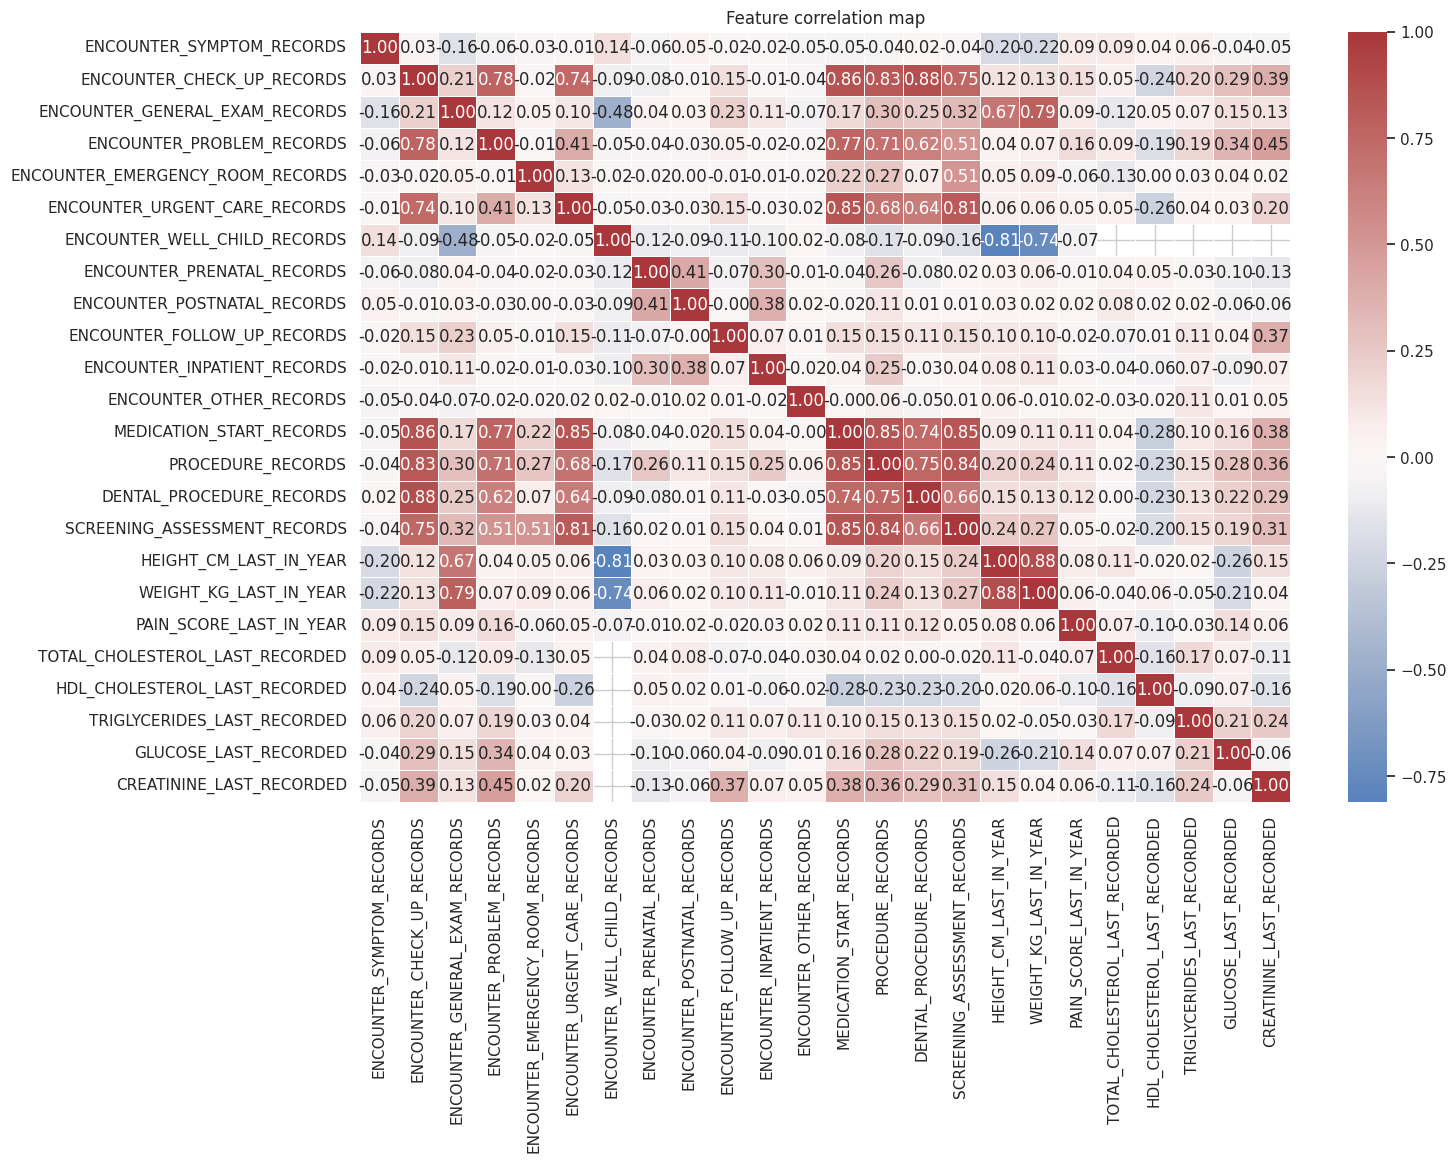

In [153]:
plt.figure(figsize=(15, 10))
corr = data[numeric_cols].corr(numeric_only=True)
sns.heatmap(corr, cmap="vlag", center=0, linewidths=0.5, annot=True,
    fmt=".2f")
plt.title("Feature correlation map")
plt.show()

when it comes to feature engineering, some features to make:
- age
- other procedures - done
- BMI - done
- list of total healthcare necounters - as currently is making this table crazy to look at

In [154]:
#Creating features

#BMI
data["BMI"] = data["WEIGHT_KG_LAST_IN_YEAR"] / ((data["HEIGHT_CM_LAST_IN_YEAR"] / 100) ** 2)
print(data["BMI"])

#List of healthcare encounter columns - combining all of the values that have "encounter" in the title to come up with one total number
encounter_cols = [
    "ENCOUNTER_SYMPTOM_RECORDS", "ENCOUNTER_CHECK_UP_RECORDS", "ENCOUNTER_GENERAL_EXAM_RECORDS", "ENCOUNTER_PROBLEM_RECORDS",
    "ENCOUNTER_EMERGENCY_ROOM_RECORDS", "ENCOUNTER_URGENT_CARE_RECORDS", "ENCOUNTER_WELL_CHILD_RECORDS", "ENCOUNTER_PRENATAL_RECORDS",
    "ENCOUNTER_POSTNATAL_RECORDS", "ENCOUNTER_FOLLOW_UP_RECORDS", "ENCOUNTER_INPATIENT_RECORDS",
    "ENCOUNTER_OTHER_RECORDS"
]

#total healthcare encounters
data["TOTAL_HEALTHCARE_ENCOUNTERS"] = data[encounter_cols].sum(axis=1)
print (data["TOTAL_HEALTHCARE_ENCOUNTERS"])
#FULL DISCLOSURE I NEEDED AI TO HELP ME CORRECT MY CODE HERE


#TOTAL NON DENTAL procedures = procedures - dental - screening
data["TOTAL_NON_DENTAL/SCREENING_PROCEDURES"] = (data["PROCEDURE_RECORDS"] - data["DENTAL_PROCEDURE_RECORDS"] - data["SCREENING_ASSESSMENT_RECORDS"])
print(data["TOTAL_NON_DENTAL/SCREENING_PROCEDURES"])



0      27.772802
1      27.772802
2      27.772802
3      30.301451
4      30.301451
         ...    
292    27.319068
293    27.319068
294    27.580919
295    27.580919
296    27.580919
Name: BMI, Length: 297, dtype: float64
0      7
1      3
2      6
3      1
4      5
      ..
292    3
293    3
294    2
295    2
296    2
Name: TOTAL_HEALTHCARE_ENCOUNTERS, Length: 297, dtype: int64
0       5
1       3
2       5
3       0
4      56
       ..
292     0
293     1
294     0
295     1
296     1
Name: TOTAL_NON_DENTAL/SCREENING_PROCEDURES, Length: 297, dtype: int64


##Relook at the visualisation post feature engineering

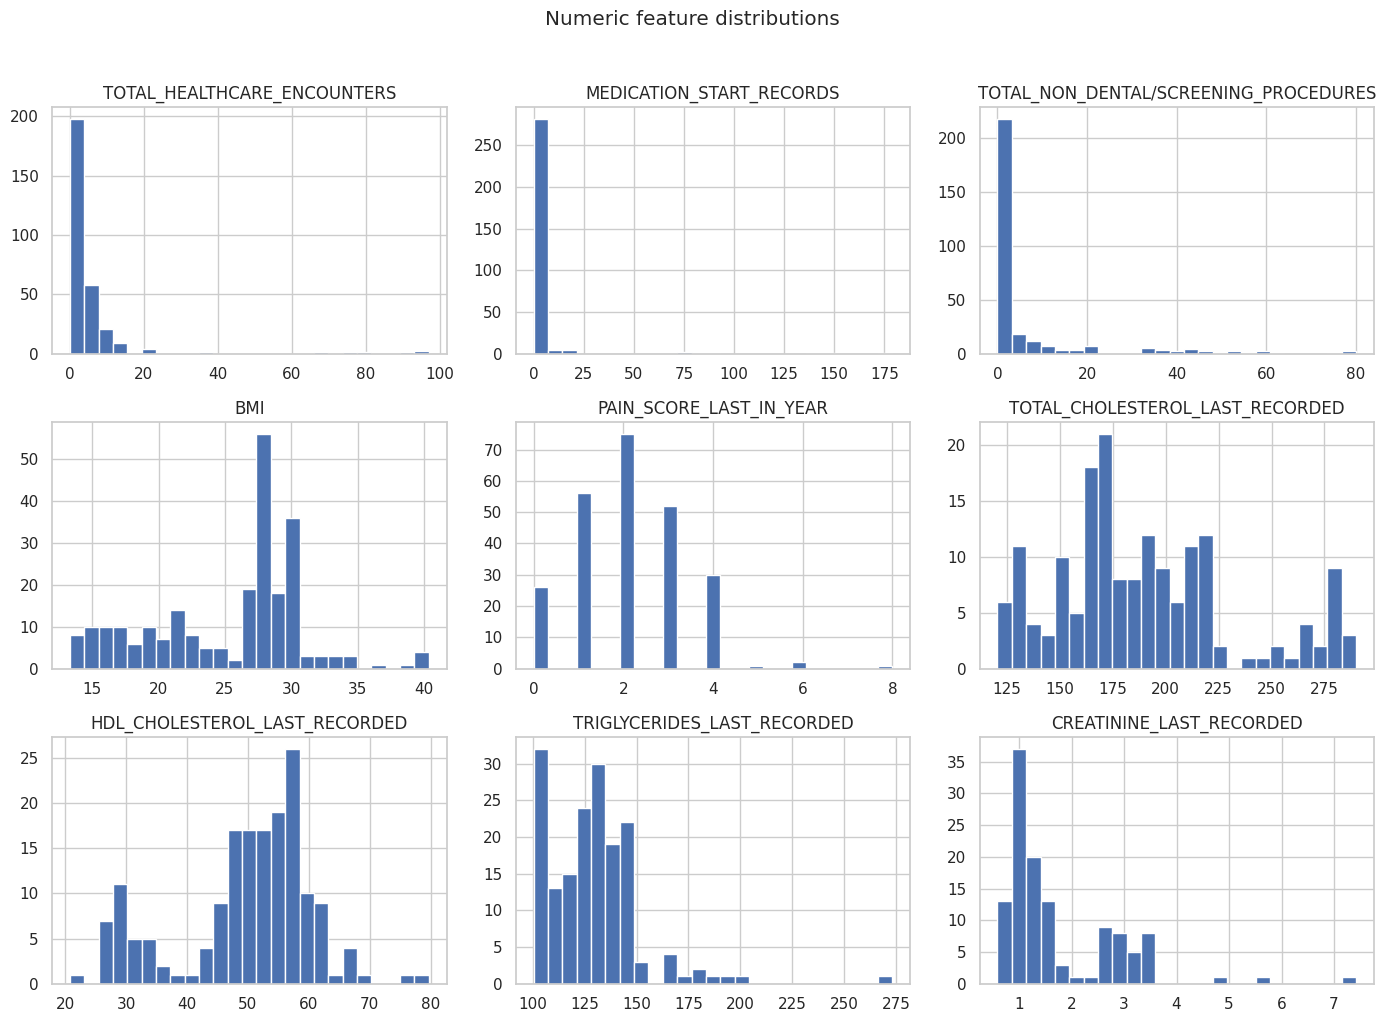

In [155]:
#making a histogram
numeric_cols = ["TOTAL_HEALTHCARE_ENCOUNTERS", "MEDICATION_START_RECORDS",
                "TOTAL_NON_DENTAL/SCREENING_PROCEDURES", "BMI", "PAIN_SCORE_LAST_IN_YEAR", "TOTAL_CHOLESTEROL_LAST_RECORDED",
                "HDL_CHOLESTEROL_LAST_RECORDED", "TRIGLYCERIDES_LAST_RECORDED",
                "CREATININE_LAST_RECORDED"
]

data[numeric_cols].hist(figsize=(14, 10), bins=25)
plt.suptitle("Numeric feature distributions", y=1.02)
plt.tight_layout()
plt.show()

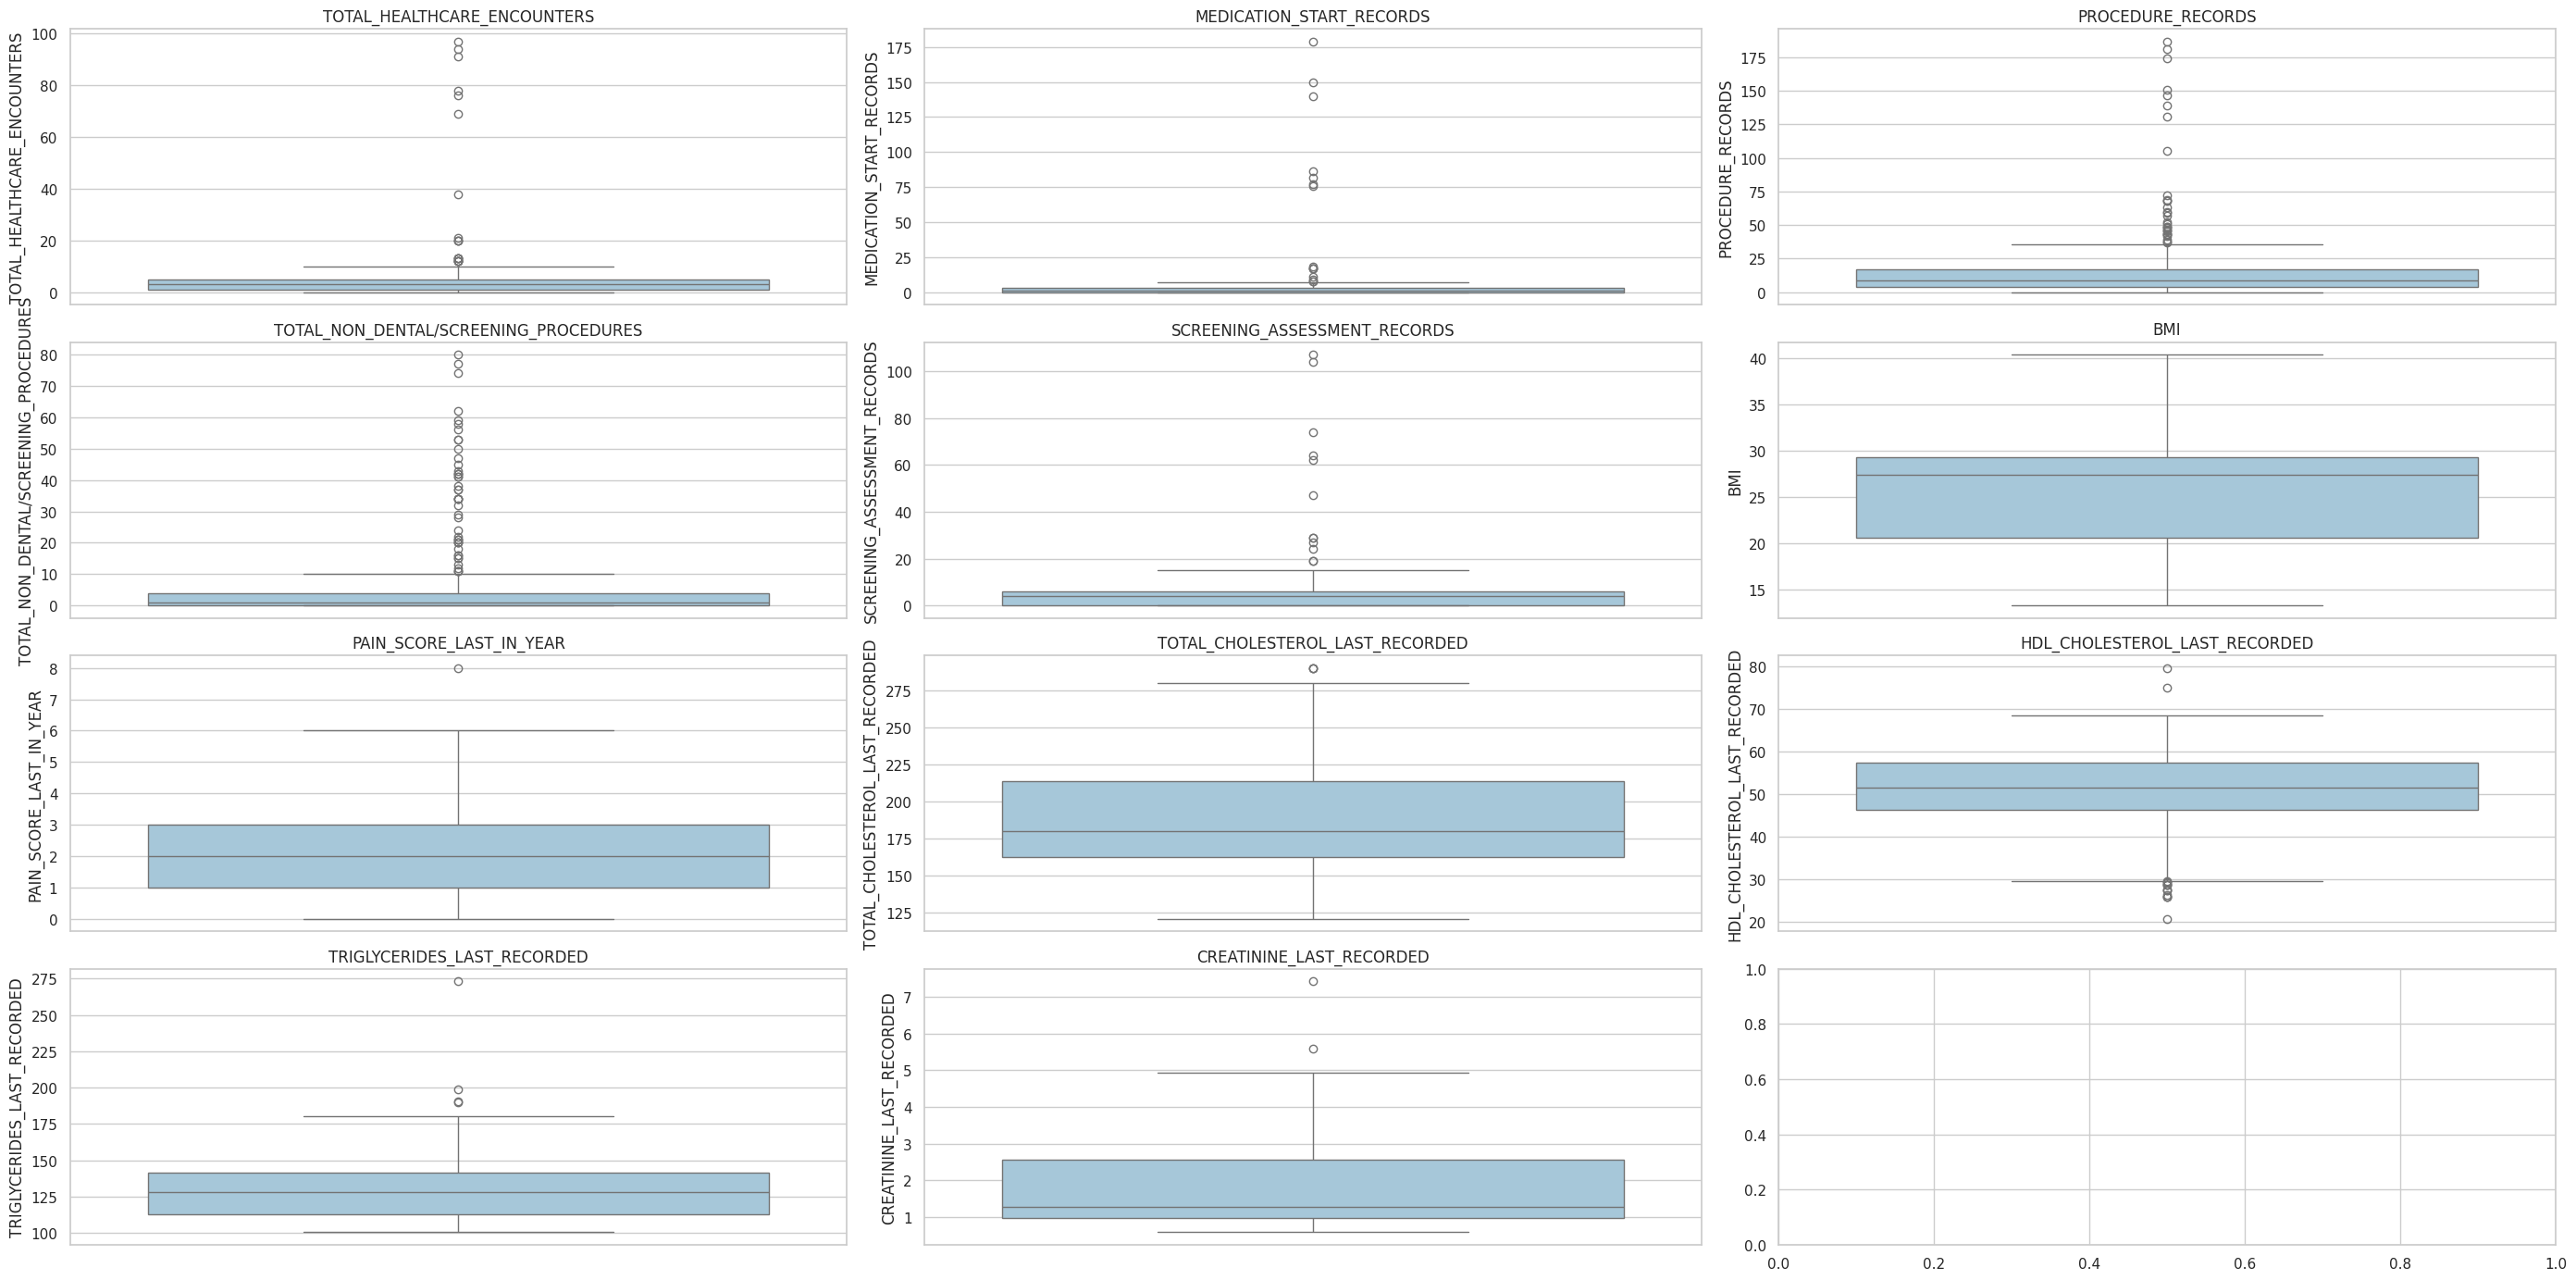

In [156]:
# Box plots for outlier inspection.
features_to_boxplot = ["TOTAL_HEALTHCARE_ENCOUNTERS", "MEDICATION_START_RECORDS", "PROCEDURE_RECORDS",
                       "TOTAL_NON_DENTAL/SCREENING_PROCEDURES", "SCREENING_ASSESSMENT_RECORDS",
                       "BMI", "PAIN_SCORE_LAST_IN_YEAR", "TOTAL_CHOLESTEROL_LAST_RECORDED",
                       "HDL_CHOLESTEROL_LAST_RECORDED",
                       "TRIGLYCERIDES_LAST_RECORDED", "CREATININE_LAST_RECORDED"
]

fig, axes = plt.subplots(4, 3, figsize=(28, 14))
for ax, col in zip(axes.ravel(), features_to_boxplot):
    sns.boxplot(y=data[col], ax=ax, color="#9ecae1")
    ax.set_title(col)
plt.tight_layout()
plt.show()

BMI looks a lot more sensivle, pain and bloods look more reasonable.
Healthcare encounters and records (procedures, medications, screening) etc all quite varied with high number still - to discuss with the team.

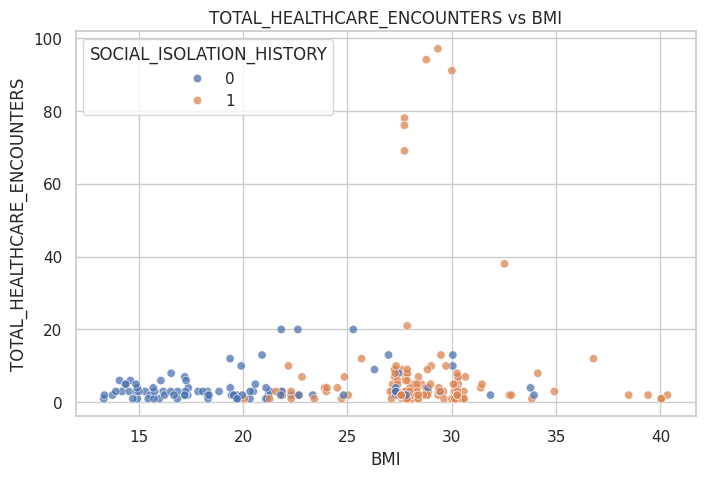

In [157]:
x_col = "BMI"
y_col = "TOTAL_HEALTHCARE_ENCOUNTERS"
hue_col = "SOCIAL_ISOLATION_HISTORY"

plt.figure(figsize=(8, 5))
sns.scatterplot(data=data.copy(), x=x_col, y=y_col, hue=hue_col, alpha=0.75)
plt.title(f"{y_col} vs {x_col}")
plt.show()

An interesting potential relationship here between social isolation and BMI

In [158]:
# HOW TO START PROCESSING OUT DATA TO INCLUDE OUR NEW FEATURES

ID_COLUMNS = ["PATIENT_ID"]

DEFAULT_FEATURES = [
    "BMI", "SEX", "RACE", "BIRTH_DATE", "YEAR","PAIN_SCORE_LAST_IN_YEAR",
    "TOTAL_CHOLESTEROL_LAST_RECORDED", "HDL_CHOLESTEROL_LAST_RECORDED",
    "TRIGLYCERIDES_LAST_RECORDED","CREATININE_LAST_RECORDED",
    "TOTAL_HEALTHCARE_ENCOUNTERS", "TOTAL_NON_DENTAL/SCREENING_PROCEDURES",
    "OBESITY_HISTORY", "PREDIABETES_HISTORY",
    "HYPERTENSION_HISTORY", "ISCHEMIC_HEART_DISEASE_HISTORY", "HYPERLIPIDEMIA_HISTORY",
    "CHRONIC_PAIN_HISTORY", "ASTHMA_HISTORY", "CHRONIC_KIDNEY_DISEASE_HISTORY", "STRESS_HISTORY",
    "SOCIAL_ISOLATION_HISTORY", "UNEMPLOYMENT_HISTORY", "HOUSING_UNSATISFACTORY_HISTORY"
]

# Variant space: remove or add columns and observe how clusters change.
FEATURES_TO_USE = DEFAULT_FEATURES.copy()

X = data[FEATURES_TO_USE].copy()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Ensure categorical missing values are np.nan, not pd.NA, before SimpleImputer.
for col in categorical_features:
    X[col] = X[col].map(lambda value: np.nan if pd.isna(value) else str(value))

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['BMI', 'YEAR', 'PAIN_SCORE_LAST_IN_YEAR', 'TOTAL_CHOLESTEROL_LAST_RECORDED', 'HDL_CHOLESTEROL_LAST_RECORDED', 'TRIGLYCERIDES_LAST_RECORDED', 'CREATININE_LAST_RECORDED', 'TOTAL_HEALTHCARE_ENCOUNTERS', 'TOTAL_NON_DENTAL/SCREENING_PROCEDURES', 'OBESITY_HISTORY', 'PREDIABETES_HISTORY', 'HYPERTENSION_HISTORY', 'ISCHEMIC_HEART_DISEASE_HISTORY', 'HYPERLIPIDEMIA_HISTORY', 'CHRONIC_PAIN_HISTORY', 'ASTHMA_HISTORY', 'CHRONIC_KIDNEY_DISEASE_HISTORY', 'STRESS_HISTORY', 'SOCIAL_ISOLATION_HISTORY', 'UNEMPLOYMENT_HISTORY', 'HOUSING_UNSATISFACTORY_HISTORY']
Categorical features: ['SEX', 'RACE', 'BIRTH_DATE']


In [159]:
# check na in X
X.isna().sum()

,0
BMI,55
SEX,0
RACE,0
BIRTH_DATE,0
YEAR,0
PAIN_SCORE_LAST_IN_YEAR,54
TOTAL_CHOLESTEROL_LAST_RECORDED,128
HDL_CHOLESTEROL_LAST_RECORDED,128
TRIGLYCERIDES_LAST_RECORDED,128
CREATININE_LAST_RECORDED,176


In [160]:
# Filter feature lists to only include columns actually present in X
numeric_features_cleaned = [col for col in numeric_features if col in X.columns]
categorical_features_cleaned = [col for col in categorical_features if col in X.columns]

# Safely convert datetime columns like BIRTH_DATE to string format so OneHotEncoder can process them
for col in categorical_features_cleaned:
    if pd.api.types.is_datetime64_any_dtype(X[col]):
        X[col] = X[col].dt.strftime('%Y-%m-%d')

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features_cleaned),
        ("cat", categorical_pipeline, categorical_features_cleaned)
    ]
)

X_prepared = preprocessor.fit_transform(X)
print("Prepared feature matrix shape:", X_prepared.shape)

Prepared feature matrix shape: (297, 122)


For K=2, cluster sizes are 84, 213
For K=3, cluster sizes are 185, 77, 35
For K=4, cluster sizes are 77, 13, 179, 28
For K=5, cluster sizes are 13, 21, 76, 90, 97
For K=6, cluster sizes are 76, 48, 21, 28, 111, 13
For K=7, cluster sizes are 16, 73, 38, 6, 64, 28, 72
For K=8, cluster sizes are 39, 74, 21, 33, 52, 37, 13, 28


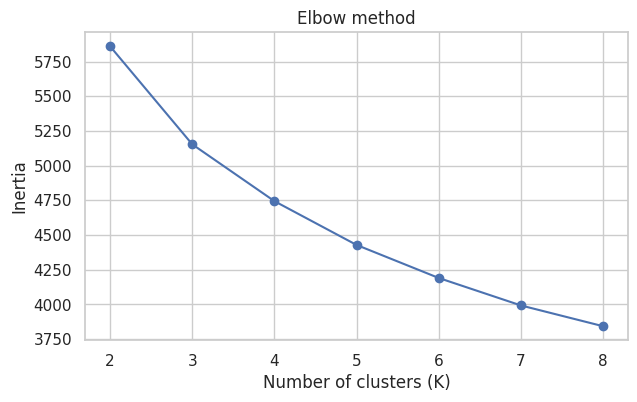

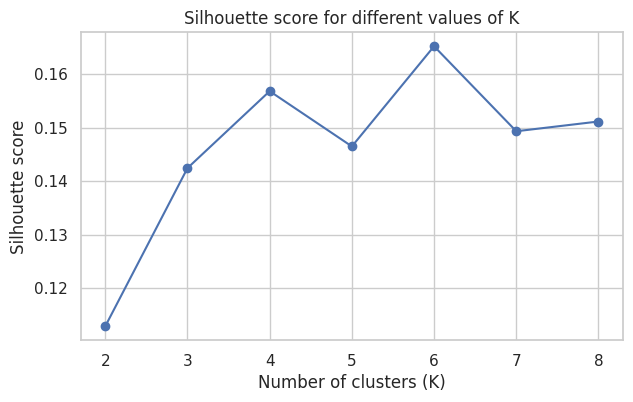

In [161]:
k_values = range(2, 9)

inertias = []
silhouette_scores = []
cluster_sizes = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_prepared)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_prepared, labels)
    )

    # Count how many observations belong to each cluster
    sizes = pd.Series(labels).value_counts().sort_index().tolist()
    cluster_sizes.append(sizes)
    print(f"For K={k}, cluster sizes are {', '.join(map(str, sizes))}")


# Plot inertia
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()


# Plot silhouette score
plt.figure(figsize=(7, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score for different values of K")
plt.show()

Choosing to look at stress history if it as target colomn

In [162]:
missing_ids = [column for column in ID_COLUMNS if column not in data.columns]
if missing_ids:
    raise KeyError(f"ID columns not found: {missing_ids}")

clean_data = data.drop_duplicates().copy()
clean_data["STRESS_HISTORY"] = pd.to_numeric(
    clean_data["STRESS_HISTORY"], errors="coerce"
)

rows_before = len(clean_data)
clean_data = clean_data.dropna(subset=["STRESS_HISTORY"])
print(f"Removed {rows_before - len(clean_data)} rows with a missing/non-numeric target.")
print("Cleaned shape:", clean_data.shape)

Removed 0 rows with a missing/non-numeric target.
Cleaned shape: (297, 55)


In [163]:
y = clean_data["STRESS_HISTORY"].copy()
X = clean_data.drop(columns=["STRESS_HISTORY"] + ID_COLUMNS).copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

print(f"Number of observations: {X.shape[0]}")
print(f"Number of predictor features: {X.shape[1]}")

Feature matrix shape: (297, 53)
Target shape: (297,)


,BIRTH_DATE,SEX,RACE,YEAR,PERIOD_START,PERIOD_END,RECORD_CUTOFF_DATE,ENCOUNTER_SYMPTOM_RECORDS,ENCOUNTER_CHECK_UP_RECORDS,ENCOUNTER_GENERAL_EXAM_RECORDS,...,HYPERLIPIDEMIA_HISTORY,CHRONIC_PAIN_HISTORY,ASTHMA_HISTORY,CHRONIC_KIDNEY_DISEASE_HISTORY,SOCIAL_ISOLATION_HISTORY,UNEMPLOYMENT_HISTORY,HOUSING_UNSATISFACTORY_HISTORY,BMI,TOTAL_HEALTHCARE_ENCOUNTERS,TOTAL_NON_DENTAL/SCREENING_PROCEDURES
0,1981-01-20,F,white,2023,2023-01-01,2023-12-31,2026-08-25,0,0,1,...,0,0,0,0,1,0,0,27.772802,7,5
1,1981-01-20,F,white,2024,2024-01-01,2024-12-31,2026-08-25,0,0,1,...,0,0,0,0,1,0,0,27.772802,3,3
2,1981-01-20,F,white,2025,2025-01-01,2025-12-31,2026-08-25,0,1,1,...,0,0,0,0,1,0,0,27.772802,6,5
3,1972-01-11,F,white,2023,2023-01-01,2023-12-31,2026-08-19,0,0,1,...,0,1,0,0,1,0,0,30.301451,1,0
4,1972-01-11,F,white,2024,2024-01-01,2024-12-31,2026-08-19,0,2,1,...,0,1,0,0,1,0,0,30.301451,5,56


Number of observations: 297
Number of predictor features: 53


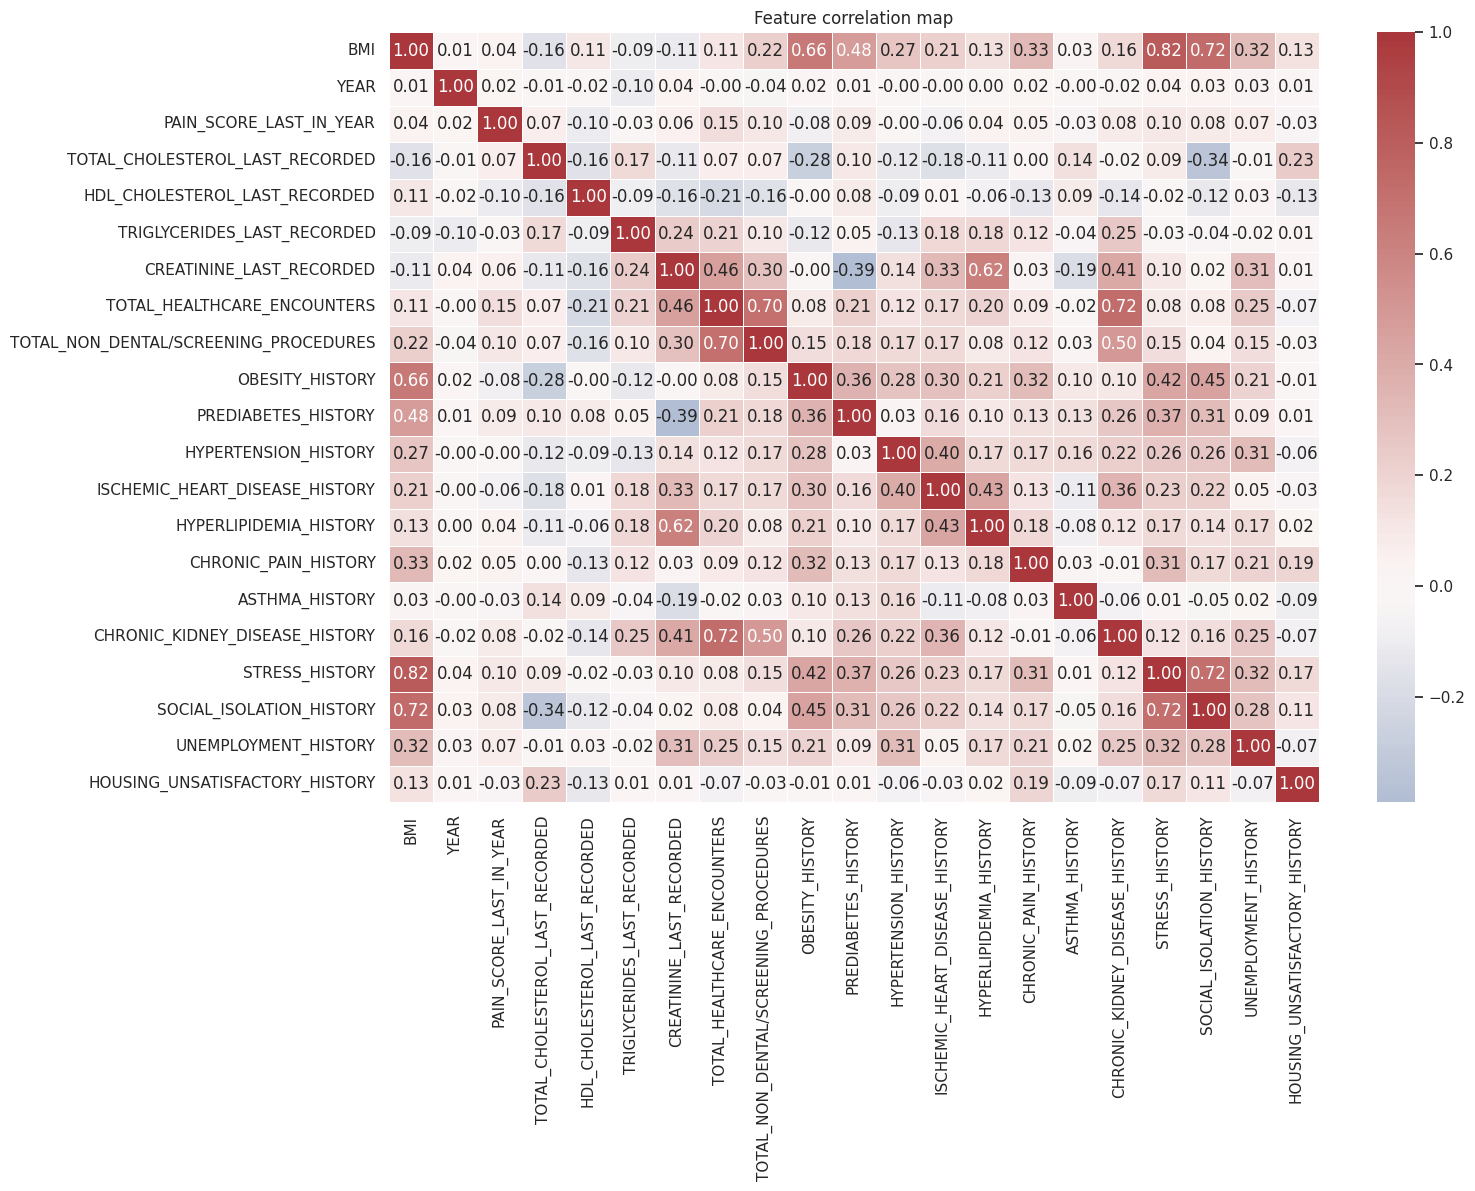

In [164]:
plt.figure(figsize=(15, 10))
corr = data[numeric_features].corr(numeric_only=True)
sns.heatmap(corr, cmap="vlag", center=0, linewidths=0.5, annot=True,
    fmt=".2f")
plt.title("Feature correlation map")
plt.show()

Possibly some relationships between BMI, stress, social isolation and unemployment
CKD also having fairly strong correlations with  having to have more total healthcare encounters

In [165]:
CHOSEN_K = 4

kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=20)
data["kmeans_cluster"] = kmeans.fit_predict(X_prepared)
data["kmeans_cluster"].value_counts().sort_index()

,count
kmeans_cluster,
0,21
1,186
2,77
3,13


Chose K = 4 by looking at the groups above, as per silhoette score things worsen at 5, and smallest group of 13 is stable from K = 4.

In [166]:
# Cluster profiles: numeric summaries.
cluster_profile = data.groupby("kmeans_cluster")[numeric_cols].mean().round(2)
display(cluster_profile)

# Categorical summaries.
for col in categorical_features:
    print("\n", col)
    display(pd.crosstab(data["kmeans_cluster"], data[col], normalize="index").round(2))

,TOTAL_HEALTHCARE_ENCOUNTERS,MEDICATION_START_RECORDS,TOTAL_NON_DENTAL/SCREENING_PROCEDURES,BMI,PAIN_SCORE_LAST_IN_YEAR,TOTAL_CHOLESTEROL_LAST_RECORDED,HDL_CHOLESTEROL_LAST_RECORDED,TRIGLYCERIDES_LAST_RECORDED,CREATININE_LAST_RECORDED
kmeans_cluster,,,,,,,,,
0,4.71,2.86,5.00,27.62,2.10,173.97,51.22,142.07,3.09
1,3.15,1.64,6.05,28.70,2.17,191.11,49.97,125.28,1.22
2,3.73,0.97,3.22,17.99,1.85,176.15,48.10,124.10,NaN
3,46.00,65.15,39.85,29.32,2.54,186.33,44.33,148.74,3.06



 SEX


SEX,F,M
kmeans_cluster,,
0,0.29,0.71
1,0.50,0.50
2,0.62,0.38
3,0.00,1.00



 RACE


RACE,asian,black,white
kmeans_cluster,,,
0,0.00,0.14,0.86
1,0.07,0.07,0.86
2,0.10,0.14,0.75
3,0.00,0.54,0.46



 BIRTH_DATE


BIRTH_DATE,1930-06-11,1942-04-04,1944-11-10,1948-06-15,1953-12-05,1954-05-10,1956-10-18,1960-03-25,1960-08-11,1961-02-07,...,2017-03-25,2017-05-11,2018-07-05,2018-10-03,2019-02-24,2019-03-10,2020-08-14,2023-03-25,2023-04-26,2024-02-01
kmeans_cluster,,,,,,,,,,,,,,,,,,,,,
0,0.00,0.00,0.00,0.00,0.14,0.14,0.00,0.14,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,0.02,0.02,0.00,0.02,0.00,0.00,0.00,0.00,0.02,0.02,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.04,0.04,0.04,0.04,0.04,0.04,0.04,0.04,0.04,0.03
3,0.00,0.00,0.23,0.00,0.00,0.00,0.23,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Cluster 0: cluster that is mostly white, with some black patients, more males than females, and slightly higher scores for encounters, and creatinine, but lower for cholesterol and BMI

Cluster 1: 50/50 females/males, mostly white, but some asian and black patients. Highest cholesterol and higher BMI than other groups. Good kidney function though.

Cluster 2: More females than males. Seems be be low BMI, lower overall risk factors for health e.g. lower pain scores, fewer medications, etc. Looks like lots of kids

Cluster 3:  the highest risk group. Also the group with the highest proportion of black patients. Totally male group, highest healthcare encounters etc


Note would be good to create an Age category rather than date of birth.

In [167]:
gmm = GaussianMixture(n_components=CHOSEN_K, random_state=RANDOM_STATE, covariance_type="full")
gmm_labels = gmm.fit_predict(X_prepared.toarray() if hasattr(X_prepared, "toarray") else X_prepared)
gmm_probs = gmm.predict_proba(X_prepared.toarray() if hasattr(X_prepared, "toarray") else X_prepared)

data["gmm_cluster"] = gmm_labels
data["gmm_max_probability"] = gmm_probs.max(axis=1)

display(data[["PATIENT_ID", "kmeans_cluster", "gmm_cluster", "gmm_max_probability"]].head())
print("Low-confidence GMM assignments:")
display(data.sort_values("gmm_max_probability").head(10)[["PATIENT_ID", "gmm_cluster", "gmm_max_probability", "SEX", "STRESS_HISTORY", "BMI"]])

,PATIENT_ID,kmeans_cluster,gmm_cluster,gmm_max_probability
0,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,1,0,1.0
1,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,1,0,1.0
2,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,1,0,1.0
3,029c95e2-d252-d8d3-3626-7f347182d6d7,1,0,1.0
4,029c95e2-d252-d8d3-3626-7f347182d6d7,1,0,1.0


Low-confidence GMM assignments:


,PATIENT_ID,gmm_cluster,gmm_max_probability,SEX,STRESS_HISTORY,BMI
287,f6745f8a-8107-443e-8946-3e6329d20408,1,1.0,M,1,27.339626
286,f6745f8a-8107-443e-8946-3e6329d20408,1,1.0,M,1,27.339626
285,f6745f8a-8107-443e-8946-3e6329d20408,1,1.0,M,1,27.339626
284,f6359fe4-4340-2820-8b76-593a45f5186c,0,1.0,F,1,19.910867
283,f6359fe4-4340-2820-8b76-593a45f5186c,3,1.0,F,0,19.382145
282,f6359fe4-4340-2820-8b76-593a45f5186c,3,1.0,F,0,20.343064
281,f5749532-3295-ad01-d9b5-932c997e7a01,0,1.0,F,1,30.265436
280,f5749532-3295-ad01-d9b5-932c997e7a01,0,1.0,F,1,30.265436
279,f5749532-3295-ad01-d9b5-932c997e7a01,0,1.0,F,1,30.265436
278,f30304ab-8e45-1cbd-9833-cadf568373b4,3,1.0,F,0,18.851918


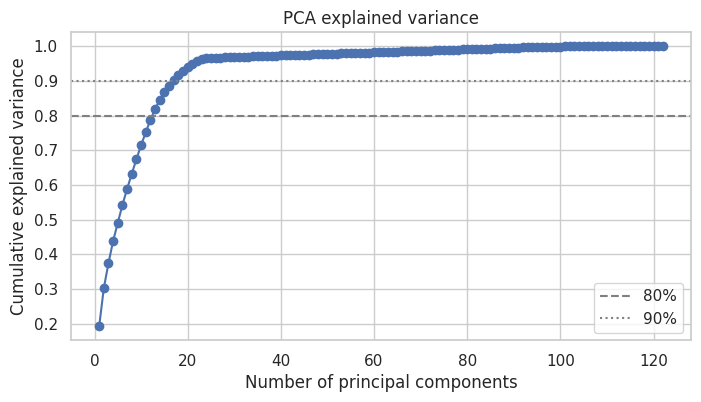

In [168]:
# PCA explained variance.
X_dense = X_prepared.toarray() if hasattr(X_prepared, "toarray") else X_prepared
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_dense)

explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_explained) + 1), cum_explained, marker="o")
plt.axhline(0.80, color="gray", linestyle="--", label="80%")
plt.axhline(0.90, color="gray", linestyle=":", label="90%")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.legend()
plt.show()

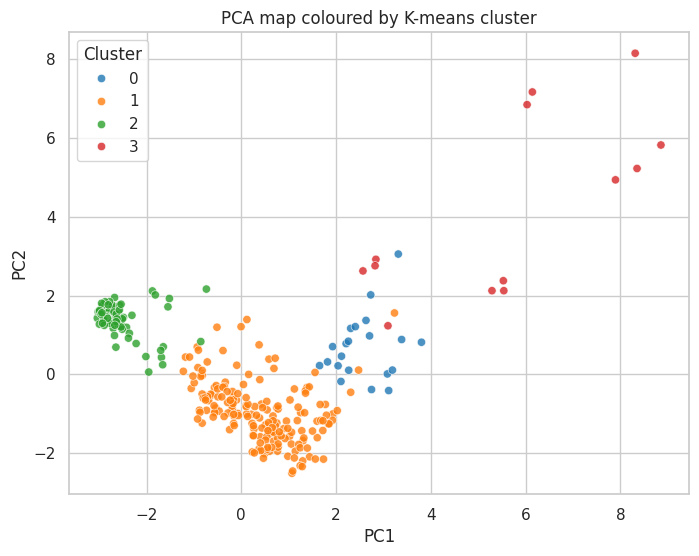

In [169]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca = pca_2d.fit_transform(X_dense)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_pca[:, 0], y=Z_pca[:, 1], hue=data["kmeans_cluster"], palette="tab10", alpha=0.8)
plt.title("PCA map coloured by K-means cluster")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()

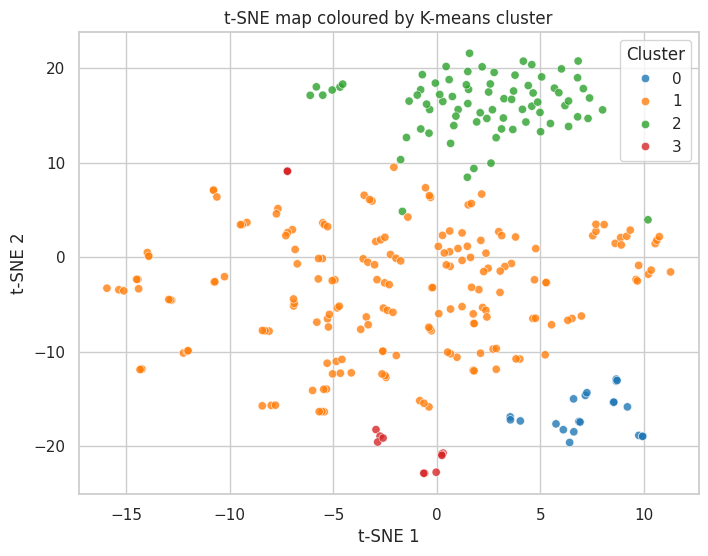

In [170]:
tsne = TSNE(
    n_components=2,
    perplexity=40,
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE
)
Z_tsne = tsne.fit_transform(X_dense)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_tsne[:, 0], y=Z_tsne[:, 1], hue=data["kmeans_cluster"], palette="tab10", alpha=0.8)
plt.title("t-SNE map coloured by K-means cluster")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cluster")
plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


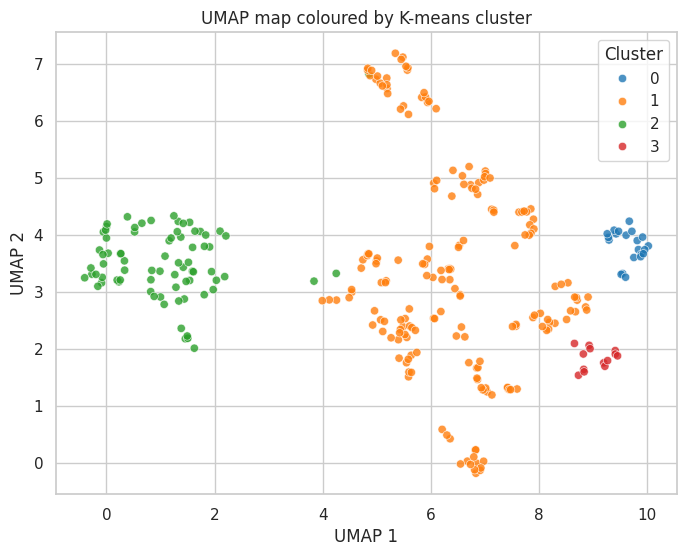

In [171]:
try:
    import umap
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.10, random_state=RANDOM_STATE)
    Z_umap = reducer.fit_transform(X_dense)

    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=Z_umap[:, 0], y=Z_umap[:, 1], hue=data["kmeans_cluster"], palette="tab10", alpha=0.8)
    plt.title("UMAP map coloured by K-means cluster")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.legend(title="Cluster")
    plt.show()
except ImportError:
    print("UMAP is not installed. This optional cell can be skipped.")